In [15]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping

In [16]:
np.random.seed(42)
tf.random.set_seed(42)

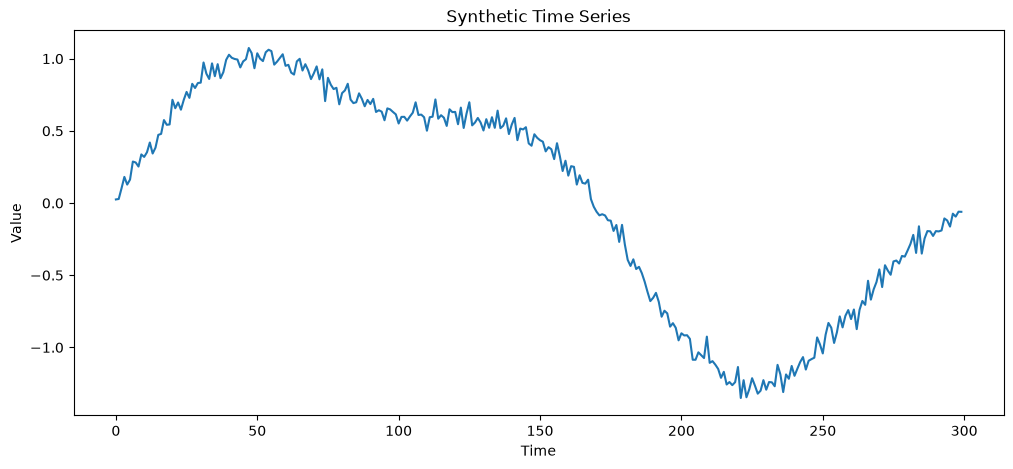

In [17]:
time = np.arange(2500)
series = (
    np.sin(time * 0.02) +
    0.3 * np.sin(time * 0.05) + 
    0.05 * np.random.normal(size=len(time))
)

series = series.astype('float32')

plt.figure(figsize=(12, 5))
plt.plot(time[:300], series[:300])
plt.title("Synthetic Time Series")
plt.xlabel("Time")
plt.ylabel("Value")
plt.show()

In [18]:
window_size = 20
X, y, target_indices = [], [], []

In [19]:
for i in range(len(series) - window_size):
    X.append(series[i : i + window_size])
    y.append(series[i + window_size])
    target_indices.append(i + window_size)

In [20]:
X = np.array(X, dtype='float32')
y = np.array(y, dtype='float32')
target_indices = np.array(target_indices)

In [21]:
X = X.reshape(-1, window_size, 1)
print(X.shape)
print(y.shape)

(2480, 20, 1)
(2480,)


In [22]:
train_end = int(len(series) * 0.70)
val_end = int(len(series) * .85)

train_mask = target_indices < train_end
val_mask = (
    (target_indices >= train_end) 
    &
    (target_indices < val_end)
)

test_mask = target_indices >= val_end

In [23]:
X_train = X[train_mask]
y_train = y[train_mask]

X_val = X[val_mask]
y_val = y[val_mask]

X_test = X[test_mask]
y_test = y[test_mask]

In [24]:
print(len(X_train))
print(len(X_test))
print(len(X_val))

1730
375
375


In [25]:
print(len(y_train))
print(len(y_test))
print(len(y_val))

1730
375
375


In [26]:
def build_model(model_type):
    model = models.Sequential()
    
    model.add(
        layers.Input(shape=(window_size, 1))
    )

    if model_type == "SimpleRNN":
        model.add(
            layers.SimpleRNN(32, activation='tanh')
        )
    
    elif model_type == 'LSTM':
        model.add(
            layers.LSTM(32, activation='tanh')
        )

    elif model_type == 'GRU':
        model.add(
            layers.GRU(32, activation='tanh')
        )

    model.add(layers.Dense(1))

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss='mse',
        metrics=['mae']
    )

    return model

In [27]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    min_delta=0.0001,
    restore_best_weights=True,
    verbose=1
)

model_types = ['SimpleRNN', 'LSTM', 'GRU']

trained_models = {}
histories = {}
results = {}

In [28]:
for model_type in model_types:
    print("\nTraining : ", model_type)
    tf.keras.utils.set_random_seed(42)

    model = build_model(model_type)
    model.summary()

    history = model.fit(
        X_train, y_train,
        validation_data = (X_val, y_val),
        epochs = 30, 
        batch_size=32,
        callbacks = [early_stopping],
        shuffle=False,
        verbose=1
    )

    test_loss, test_mae = model.evaluate(X_test, y_test, verbose=0)

    trained_models[model_type] = model
    histories[model_type] = history

    results[model_type] = {
        'MSE' : test_loss,
        'MAE' : test_mae
    }

    print(model_type, "Test MSE", round(float(test_loss), 5))
    print(model_type, "Test MAE", round(float(test_mae), 5))


Training :  SimpleRNN


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 32)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,121 (4.38 KB)

 Trainable params: 1,121 (4.38 KB)

 Non-trainable params: 0 (0.00 B)

... (9 outputs left out)

 Total params: 3,393 (13.25 KB)

 Trainable params: 3,393 (13.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.1639 - mae: 0.3107 - val_loss: 0.0067 - val_mae: 0.0659
Epoch 2/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0072 - mae: 0.0684 - val_loss: 0.0060 - val_mae: 0.0617
Epoch 3/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0062 - mae: 0.0637 - val_loss: 0.0057 - val_mae: 0.0602
Epoch 4/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0059 - mae: 0.0620 - val_loss: 0.0054 - val_mae: 0.0587
Epoch 5/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0056 - mae: 0.0604 - val_loss: 0.0052 - val_mae: 0.0574
Epoch 6/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0054 - mae: 0.0591 - val_loss: 0.0050 - val_mae: 0.0562
Epoch 7/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0052 - mae: 0.0579 - val_loss: 0.0048 - val_mae: 0.0552
Epoch 8/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0050 - mae: 0.0567 - val_loss: 0.0047 - val_mae: 0.0541
Epoch 9/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0048 - mae: 

In [29]:
print("\nFinal Model Comparision")
print('-' * 50)

for model_type, metrics in results.items():
    print(
        f"{model_type:12s} |"
        f"MSE : {metrics['MSE']:.5f} |"
        f"MAE : {metrics['MAE']:.5f}"
    )


Final Model Comparision
--------------------------------------------------
SimpleRNN    |MSE : 0.00372 |MAE : 0.04956
LSTM         |MSE : 0.00307 |MAE : 0.04489
GRU          |MSE : 0.00333 |MAE : 0.04727


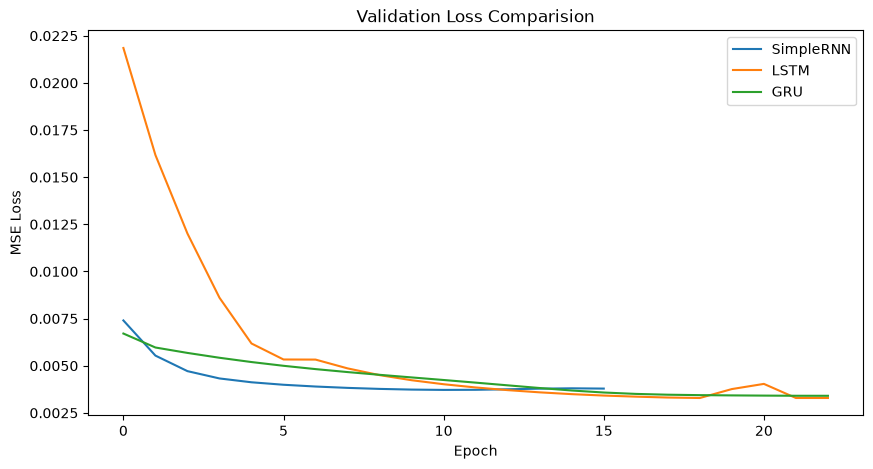

In [30]:
plt.figure(figsize=(10,5))
for model_type in model_types:
    plt.plot(
        histories[model_type].history['val_loss'],
        label=model_type
    )

plt.title("Validation Loss Comparision")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.show()

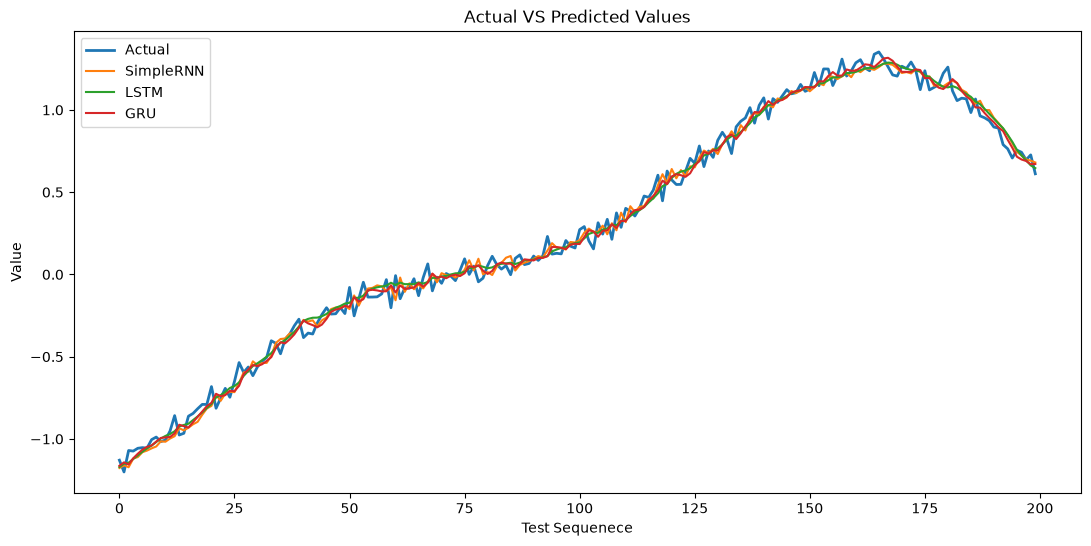

In [31]:
plt.figure(figsize=(13, 6))
plt.plot(y_test[:200], label="Actual", linewidth=2)

for model_type in model_types:
    predictions = trained_models[model_type].predict(
        X_test[:200], verbose=0
    ).flatten()
    
    plt.plot(
        predictions,
        label=model_type
    )

plt.title("Actual VS Predicted Values")
plt.xlabel("Test Sequenece")
plt.ylabel("Value")
plt.legend()
plt.show()

In [32]:
latest_window = series[-window_size:].reshape(
    1, window_size, 1
)

print("\nNEXT VALUE PREDICTIONS")
for model_type in model_types:
    next_value = trained_models[model_type].predict(
        latest_window, 
        verbose=0
    )[0, 0]

    print(
        model_type,
        "predictions:",
        round(float(next_value), 4)
    )


NEXT VALUE PREDICTIONS
SimpleRNN predictions: -0.4324
LSTM predictions: -0.4665
GRU predictions: -0.4553
